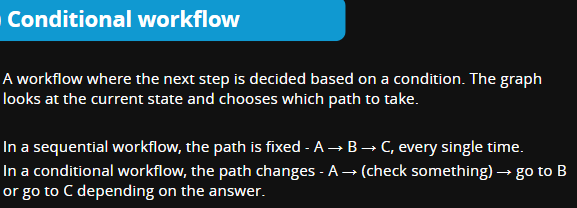

### This is how conditions Looks Like ↓

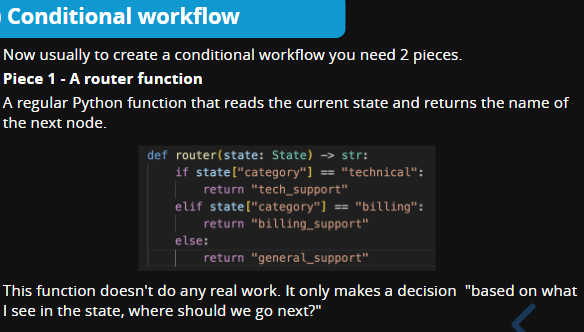

### This is how edge route to agents based on conditions ↓

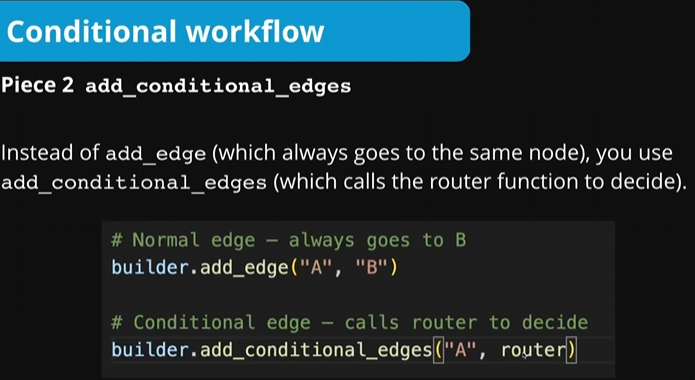


---

### Project 3: Smart College Chatbot 

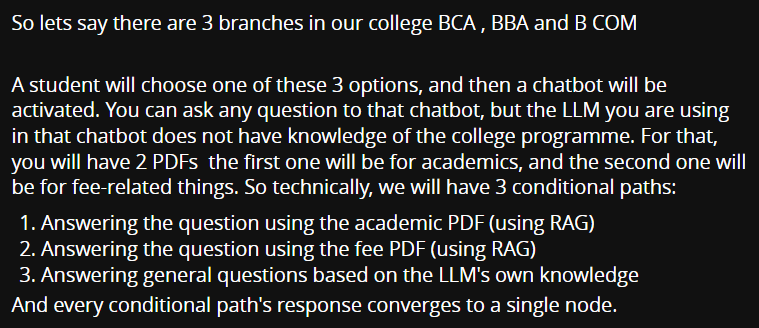



---

#### Woooooooooo
we are ging to use RAG also in this project. So that we feed college data like fee structure , policy

---

Setup

In [1]:
import os 
from typing import TypedDict, Annotated # Making State
from langgraph.graph.message import add_messages  # Storing messages like Human,AI,Tool like langchain
from langgraph.graph import StateGraph , START , END # Making pipeline
from langchain_groq import ChatGroq # LLM 
from langchain_community.document_loaders import PyPDFLoader # extract text from pdf
from langchain_text_splitters import RecursiveCharacterTextSplitter # for splitting/chunking the pdf text
from langchain_huggingface import HuggingFaceEmbeddings   # for making embeddings
from langchain_community.vectorstores import FAISS  # locally store rag
# FAISS doesnot make folder like chromaDB ir directly run on ram temproraliy

from dotenv import load_dotenv 
load_dotenv()


c:\Users\ATUL\Desktop\Agentic_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\ATUL\AppData\Local\Temp\ipykernel_26904\1675050165.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader # extract text from pdf


True

### Building Rag 

In [2]:
# Initialise Embedding Model
embeddings = HuggingFaceEmbeddings(model_name = "sentence-transformers/all-MiniLM-L6-v2" )

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3037.34it/s]


Function To make PDF embeddings

In [ ]:
def build_retriver(pdf_path : str):
    loader = PyPDFLoader(pdf_path)
    document = loader.load()

    splitter = RecursiveCharacterTextSplitter(
        chunk_size = 800, 
        chunk_overlap = 100
        )
    
    chunks = splitter.split_documents(document)

    vectorstore = FAISS.from_documents(chunks,embeddings)

    return vectorstore.as_retriever(search_kwargs = {"k":4})

Making RAG storage and retriever

In [4]:

acedemic_retriever = build_retriver("academics_handbook.pdf")
fee_retriever = build_retriver("fee_structure.pdf")

Initialise The Model

In [5]:
llm = ChatGroq(model="llama-3.3-70b-versatile", temperature=0.4)

State/public_storage Creation

In [ ]:

class State(TypedDict):
    programme : str   # BBA , BTech etc to tell he was  talking to which type of student
    messages : Annotated[list,add_messages] # to store message History like Human msg , AI msg , Tool Msg
    # Note add_messages is a prebuid function which we have imported || act as reducer
    query_type : str # fee , academics
    retrieved_context : str 


---

### Node : 1 -> Classifier Node -> 
#### To classify the user query and return query_type like fee_structure, academics, general etc.

In [7]:
def classifier_node(state : State) -> dict:
    """Look at the latest user message and decide which path to take."""

    last_message = state['messages'][-1].content

    prompt = (
        "Classify the following student query into exactly one category: "
        "'academic', 'fee', or 'general'.\n\n"
        "Use 'academic' for questions about attendance, exams, grading, credits, "
        "promotion, course structure, summer training, or degree requirements.\n"
        "Use 'fee' for questions about tuition, payment, refund, late charges, "
        "scholarships, or any money-related topic.\n"
        "Use 'general' for greetings, casual talk, or anything not related to "
        "the college rules or fee.\n\n"
        f"Query: {last_message}\n\n"
        "Return only one word: academic, fee, or general."
    )

    response = llm.invoke(prompt)
    category = response.content.strip().lower()

    if "academic" in category:
        category = "academic"
    elif "fee" in category:
        category = "fee"
    else:
        category = "general"
    
    return {"query_type" : category}

### Node 2 : Acedimic details
It use the acedimic_retriever RAG and use to answer acedimic related query

In [8]:
def academic_rag_node(state: State) -> dict:
    """Retrieves relevant chunks from the academics handbook."""
    query = state["messages"][-1].content
    docs = acedemic_retriever.invoke(query)
    context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_context": context}

### Node 3 : Fee Structure
Use FEE rag and return output

In [9]:
def fee_rag_node(state: State) -> dict:
    """Retrieves relevant chunks from the fee structure PDF."""
    query = state["messages"][-1].content
    docs = fee_retriever.invoke(query)
    context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_context": context}

### Node 4 : General Questions
If question is neither from academics and fee

In [10]:
def general_node(state: State) -> dict:
    """Answers directly using the LLM's own knowledge, no retrieval needed."""
    return {"retrieved_context": "NO_RETRIEVAL_NEEDED"}
# NO_RETRIEVAL_NEEDED use as a conditional statement below

### Node 5 : Final Response Writer Using all the Context generated by the fee,general,academic nodes

In [11]:
def response_node(state: State) -> dict:
    """Generates the final answer, personalized using the student's programme."""
    query = state["messages"][-1].content
    programme = state.get("programme", "Unknown")
    context = state["retrieved_context"]

    if context == "NO_RETRIEVAL_NEEDED":
        prompt = (
            f"You are a friendly college assistant talking to a {programme} student. "
            f"Answer this question using your own general knowledge:\n\n{query}"
        )
    else:
        prompt = (
            f"You are a college assistant helping a {programme} student. "
            f"Use the following context from the official college documents to answer "
            f"the question accurately. If the context mentions specific figures for "
            f"different programmes, highlight the one relevant to {programme} if possible.\n\n"
            f"Context:\n{context}\n\n"
            f"Question: {query}\n\n"
            f"Give a clear, friendly, and precise answer."
        )

    response = llm.invoke(prompt)
    return {"messages": [("ai", response.content.strip())]}



---

### Creating the Route Functions

In [12]:
# Note that tha names which this router return should be same as We name them while Adding Nodes
def route_query(state:State):
    if state['query_type'] == 'academic':
        return "academic_rag"
    elif state['query_type'] == "fee":
        return "fee_rag"
    else:
        return "general"

Initialise Graph

In [13]:
graph = StateGraph(State)

Adding Nodes

In [14]:
graph.add_node("classifier",classifier_node)
graph.add_node("academic_rag",academic_rag_node)
graph.add_node("fee_rag",fee_rag_node)
graph.add_node("general",general_node)
graph.add_node("response",response_node)


Making Edges

In [15]:
# Firstly we initialise the classifier so that if classify use want which type of answer
graph.add_edge(START,"classifier")


# It will send the query type to the router and router route to the fee node , register node , general node
graph.add_conditional_edges(
    "classifier",route_query
)


Adding Edges

In [16]:
# Now after the router send to node - node give reponse -> now this response will be send to response node to generate final node
graph.add_edge("academic_rag","response")
graph.add_edge("fee_rag","response")
graph.add_edge("general","response")

# Now the response node will be activated And this is the end
graph.add_edge("response",END)


Compile The graph

In [17]:
app = graph.compile()

---

## Final Running

In [ ]:

print("welcome to the College assistant \n\n")

print("which programe are you in ")
print("1. BCA")
print("2. BBA")
print("3. B.com (H)")

choice = input("\nEnter 1, 2 or 3 ")

programme_map = {
    "1": "BCA",
    "2": "BBA",
    "3": "B.Com (H)"
}
student_programme = programme_map.get(choice, "BCA")

print(f"\nGreat! You're set as a {student_programme} student.")

while True:
    user_query = input("You:  ")

    if user_query.lower() in ["exit","quit"]:
        break
    
    result = app.invoke({
        "programme": student_programme,
        "messages": [("human",user_query)]
    })

    print(f"Assistant : {result['messages'][-1].content}")

welcome to the College assistant 


which programe are you in 
1. BCA
2. BBA
3. B.com (H)

Great! You're set as a BCA student.
Assistant : Hello! I'm doing great, thanks for asking! It's wonderful to connect with you, a BCA student. I hope your studies are going well and you're enjoying your time in college. How about you, how's your day going so far? Are you having any trouble with your coursework or is there something specific you'd like to talk about? I'm all ears and here to help!
Assistant : As a BCA student, your first-year fee is **Rs. 1,20,000**. This includes:

- Academic Fee (Tuition): **Rs. 85,000**
- University Fee: **Rs. 22,000**
- Student Activity Fee: **Rs. 8,000**
- Security Deposit (Refundable): **Rs. 5,000**

Please note that a portion of this fee will be collected by the University during the counseling and admission process, and the remaining balance must be deposited at the Institute within 15 days of admission or as per the schedule notified by the University.
Ass

---
---
---

#  Congratulations I did It :)